#### SUPPLY CHAIN INVENTORY OPTIMIZATION PROJECT

## Project Overview

This project will analyze how demand forecasting and supplier lead-time variability affect inventory management and stockout risk across multiple warehouses. Using the supply chain dataset, the analysis will examine historical sales, inventory levels, demand forecasts, supplier lead times, reorder points, order quantities and stockout occurrences across different SKUs, suppliers, warehouses and regions.

The project will identify patterns and drivers of stockouts, assess how variations in supplier lead times influence inventory availability, and evaluate whether current reorder points and order quantities are aligned with actual demand. The analysis will then use these insights to identify opportunities for improving demand forecasting, inventory planning and supplier management.

The expected outcome is a data-driven inventory decision framework that can help determine appropriate inventory levels, improve replenishment decisions, reduce stockout risk and support better coordination between warehouses and suppliers.

## Key Project Objectives

1). Analyze demand patterns across SKUs and warehouses.
2). Measure supplier lead-time variability and its relationship with stockouts.
3). Evaluate inventory and reorder-point performance.
4). Identify high-risk SKUs, suppliers and warehouses.
5). Assess the effectiveness of existing demand forecasts.
6). Recommend strategies to reduce stockouts while avoiding unnecessary excess inventory.

In [1]:
pip install plotly

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
!pip install scipy statsmodels scikit-learn

In [6]:
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [7]:
# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
from pathlib import Path

# Folder for all project visualisations
IMAGE_DIR = Path("Images")
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Charts will be saved to: {IMAGE_DIR.resolve()}")


Charts will be saved to: C:\Users\pc\Documents\PC 1\Documents\JW work\python\python for data analytics and data app\MSCP\Project 1Inventory analysis\Images


In [9]:
# Load dataset using portable project-relative paths
candidate_paths = [
    Path("Data") / "supply_chain_dataset1.csv",
    Path("supply_chain_dataset1.csv"),
    Path("/mnt/data/supply_chain_dataset1.csv"),
    Path("/mnt/data/supply_chain_dataset1(1).csv")
]

data_path = next((p for p in candidate_paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "Dataset not found. Place supply_chain_dataset1.csv inside the project's Data folder "
        "or in the same folder as this notebook."
    )

df = pd.read_csv(data_path)
print(f"Dataset loaded from: {data_path.resolve()}")


Dataset loaded from: C:\Users\pc\Documents\PC 1\Documents\JW work\python\python for data analytics and data app\MSCP\Project 1Inventory analysis\supply_chain_dataset1.csv


In [10]:
# Confirm connection
print("Dataset connected successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset connected successfully!
Rows: 91250
Columns: 15


In [11]:
df.head()

,Date,SKU_ID,Warehouse_ID,Supplier_ID,Region,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,Unit_Cost,Unit_Price,Promotion_Flag,Stockout_Flag,Demand_Forecast
0,2024-01-01,SKU_1,WH_1,SUP_8,West,10,592,14,379,0,13.95,20.48,0,0,8.52
1,2024-01-02,SKU_1,WH_1,SUP_8,West,17,575,14,379,0,13.95,20.48,0,0,18.63
2,2024-01-03,SKU_1,WH_1,SUP_8,North,35,540,14,379,0,13.95,20.48,1,0,39.62
3,2024-01-04,SKU_1,WH_1,SUP_8,South,24,516,14,379,0,13.95,20.48,0,0,19.43
4,2024-01-05,SKU_1,WH_1,SUP_8,West,21,495,14,379,0,13.95,20.48,0,0,18.70


In [12]:
# Data qulaity Audit
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

for col in ['SKU_ID','Warehouse_ID','Supplier_ID','Region']:
    df[col] = df[col].str.strip().str.upper() # then revert Region to Title if needed
df['Region'] = df['Region'].str.title()

df['flag_negative_inv'] = df['Inventory_Level'] < 0
df['flag_price_error'] = df['Unit_Price'] < df['Unit_Cost']
df['flag_stockout_mismatch'] = ((df['Stockout_Flag']==1) & (df['Inventory_Level']>0))

print(df[['flag_negative_inv','flag_price_error','flag_stockout_mismatch']].sum())

df.to_csv('supply_chain_cleaned.csv', index=False)

flag_negative_inv         0
flag_price_error          0
flag_stockout_mismatch    0
dtype: int64


## Audit revealed no missing, duplicates, or inconsistent values; only Date type conversion required. Data is ready for modeling.

# 3. Exploratory Demand Analysis


The primary demand variable is `Units_Sold`.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ensure Date is datetime
df['Date'] = pd.to_datetime(df['Date'])

# Sort chronologically
df = df.sort_values(['SKU_ID', 'Warehouse_ID', 'Date']).reset_index(drop=True)

print("Dataset period:", df['Date'].min(), "to", df['Date'].max())
print("Number of SKUs:", df['SKU_ID'].nunique())
print("Number of Warehouses:", df['Warehouse_ID'].nunique())
print("Number of Suppliers:", df['Supplier_ID'].nunique())

# Overall demand statistics
print("\nDemand Statistics")
display(df['Units_Sold'].describe())

# Total demand by warehouse
warehouse_demand = (
    df.groupby('Warehouse_ID')['Units_Sold']
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

warehouse_demand.columns = ['Warehouse_ID', 'Total_Units_Sold']

display(warehouse_demand)

Dataset period: 2024-01-01 00:00:00 to 2024-12-30 00:00:00
Number of SKUs: 50
Number of Warehouses: 5
Number of Suppliers: 10

Demand Statistics


count    91250.000000
mean        20.054564
std          9.068602
min          0.000000
25%         13.000000
50%         20.000000
75%         27.000000
max         59.000000
Name: Units_Sold, dtype: float64

,Warehouse_ID,Total_Units_Sold
0,WH_1,366902
1,WH_3,366110
2,WH_2,366078
3,WH_4,365775
4,WH_5,365114


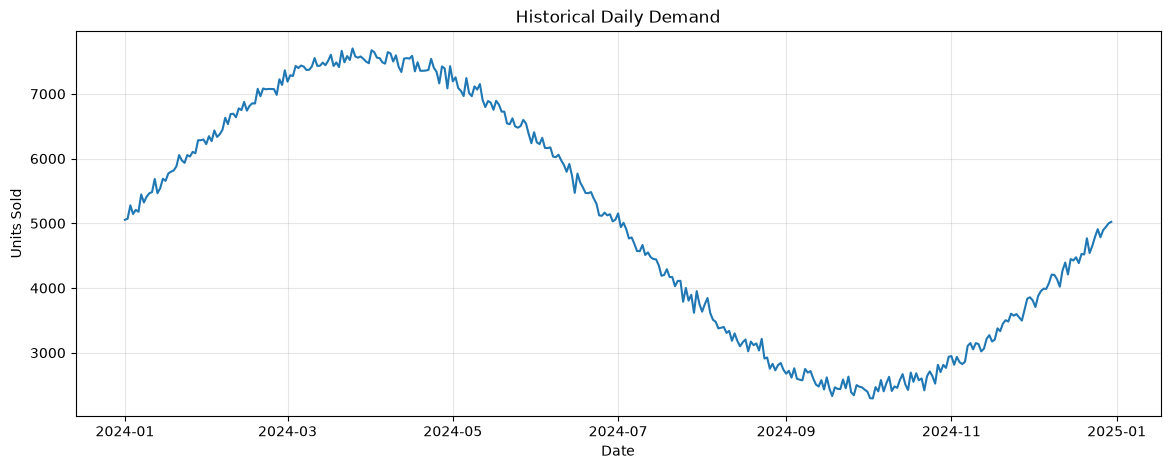

In [14]:
# Aggregate total demand by date

daily_demand = (
    df.groupby('Date', as_index=False)
      .agg(Units_Sold=('Units_Sold', 'sum'))
)

plt.figure(figsize=(14, 5))
plt.plot(daily_demand['Date'], daily_demand['Units_Sold'])
plt.title('Historical Daily Demand')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.grid(alpha=0.3)
plt.savefig(IMAGE_DIR / "01_historical_daily_demand.png", dpi=300, bbox_inches="tight")

plt.show()

### Interpretation — Historical Daily Demand
This chart shows day-to-day network demand. Peaks indicate stronger demand and troughs weaker demand, confirming that replenishment should respond to changing consumption rather than rely only on an annual average.

# 4. WEEKLY DEMAND AGGREGATION

In [15]:
weekly_demand = (
    df.set_index('Date')
      .resample('W')['Units_Sold']
      .sum()
      .reset_index()
)

weekly_demand = weekly_demand.rename(
    columns={'Units_Sold': 'Demand'}
)

display(weekly_demand.head(10))

print("Number of weekly periods:", len(weekly_demand))

,Date,Demand
0,2024-01-07,36381
1,2024-01-14,38372
2,2024-01-21,40662
3,2024-01-28,42464
4,2024-02-04,44187
5,2024-02-11,46006
6,2024-02-18,47664
7,2024-02-25,49421
8,2024-03-03,50465
9,2024-03-10,51856


Number of weekly periods: 53


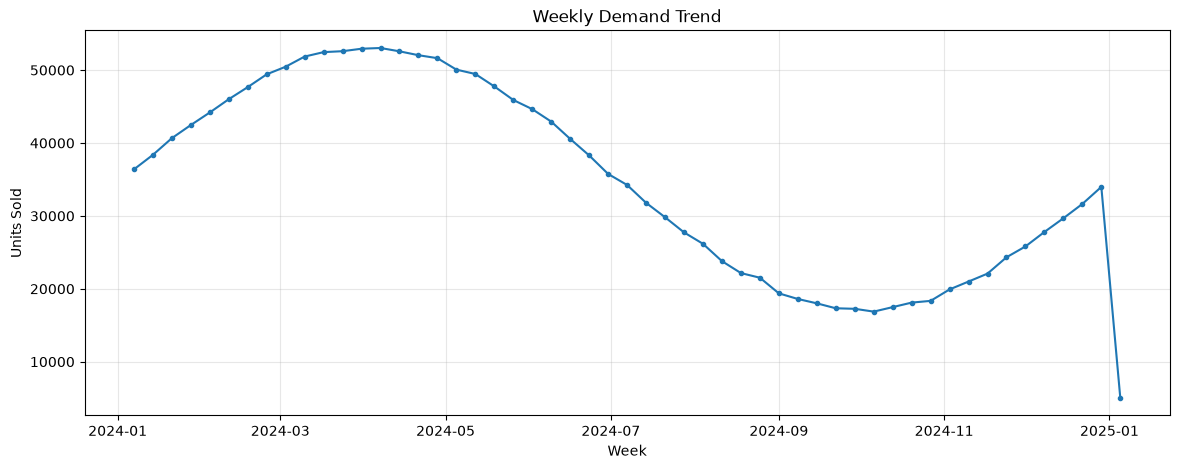

In [16]:
plt.figure(figsize=(14, 5))
plt.plot(
    weekly_demand['Date'],
    weekly_demand['Demand'],
    marker='o',
    markersize=3
)

plt.title('Weekly Demand Trend')
plt.xlabel('Week')
plt.ylabel('Units Sold')
plt.grid(alpha=0.3)

plt.savefig(IMAGE_DIR / "02_weekly_demand_trend.png", dpi=300, bbox_inches="tight")

plt.show()

### Interpretation — Weekly Demand Trend
Weekly aggregation reduces daily noise and makes the underlying demand pattern clearer. This weekly series is the basis for the 1-, 3- and 6-period forecasts.

5. Train/Test Split

In [17]:
# Keep final 6 weeks for model evaluation
test_periods = 6

train = weekly_demand.iloc[:-test_periods].copy()
test = weekly_demand.iloc[-test_periods:].copy()

print("Training periods:", len(train))
print("Testing periods:", len(test))

print("\nTraining ends:", train['Date'].max())
print("Testing starts:", test['Date'].min())

Training periods: 47
Testing periods: 6

Training ends: 2024-11-24 00:00:00
Testing starts: 2024-12-01 00:00:00


### 6. Forecast Model 1 — Moving Average

In [18]:
# MODEL 1: MOVING AVERAGE

moving_average_window = 4

ma_forecast_value = (
    train['Demand']
    .tail(moving_average_window)
    .mean()
)

ma_predictions = np.repeat(
    ma_forecast_value,
    len(test)
)

print("4-Week Moving Average Forecast:")
print(round(ma_forecast_value, 2))

4-Week Moving Average Forecast:
21830.25


### 7. Forecast Model 2 — Exponential Smoothing

In [19]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA


In [20]:
# MODEL 2: EXPONENTIAL SMOOTHING

ets_model = ExponentialSmoothing(
    train['Demand'],
    trend='add',
    seasonal=None,
    initialization_method='estimated'
)

ets_fit = ets_model.fit()

ets_predictions = ets_fit.forecast(len(test))

print("Exponential Smoothing Forecast:")
print(ets_predictions)

Exponential Smoothing Forecast:
47    25889.697369
48    27691.039569
49    29492.381769
50    31293.723970
51    33095.066170
52    34896.408370
dtype: float64


### 8. Forecast Model 3 — ARIMA

In [21]:
# MODEL 3: ARIMA


arima_model = ARIMA(
    train['Demand'],
    order=(2, 1, 2)
)

arima_fit = arima_model.fit()

arima_predictions = arima_fit.forecast(
    steps=len(test)
)

print("ARIMA Forecast:")
print(arima_predictions)

ARIMA Forecast:
47    26051.315215
48    27907.087896
49    29864.405345
50    31894.982284
51    33969.569328
52    36058.374042
Name: predicted_mean, dtype: float64


c:\Users\pc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


### 9. Model Evaluation

MAE — average forecast error in units.
RMSE — penalizes large forecasting errors.
MAPE — error as a percentage of actual demand.

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [23]:
# 9. FORECAST MODEL EVALUATION

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    nonzero = actual != 0
    mape = (np.mean(np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])) * 100
            if nonzero.any() else np.nan)
    return mae, rmse, mape

models = {
    'Moving Average': ma_predictions,
    'Exponential Smoothing': np.asarray(ets_predictions),
    'ARIMA': np.asarray(arima_predictions)
}

results = []
for model_name, prediction in models.items():
    mae, rmse, mape = calculate_metrics(test['Demand'], prediction)
    results.append({'Model': model_name, 'MAE': mae, 'RMSE': rmse, 'MAPE_%': mape})

model_results = (pd.DataFrame(results)
                 .sort_values('MAPE_%')
                 .reset_index(drop=True))

display(model_results.round({'MAE': 2, 'RMSE': 2, 'MAPE_%': 2}))


,Model,MAE,RMSE,MAPE_%
0,Moving Average,9426.50,10322.35,77.45
1,Exponential Smoothing,5245.65,12202.26,99.96
2,ARIMA,5305.77,12671.25,103.44


In [24]:
best_model = model_results.iloc[0]['Model']

print("Best forecasting model:", best_model)

Best forecasting model: Moving Average


### 10. Actual vs Forecast

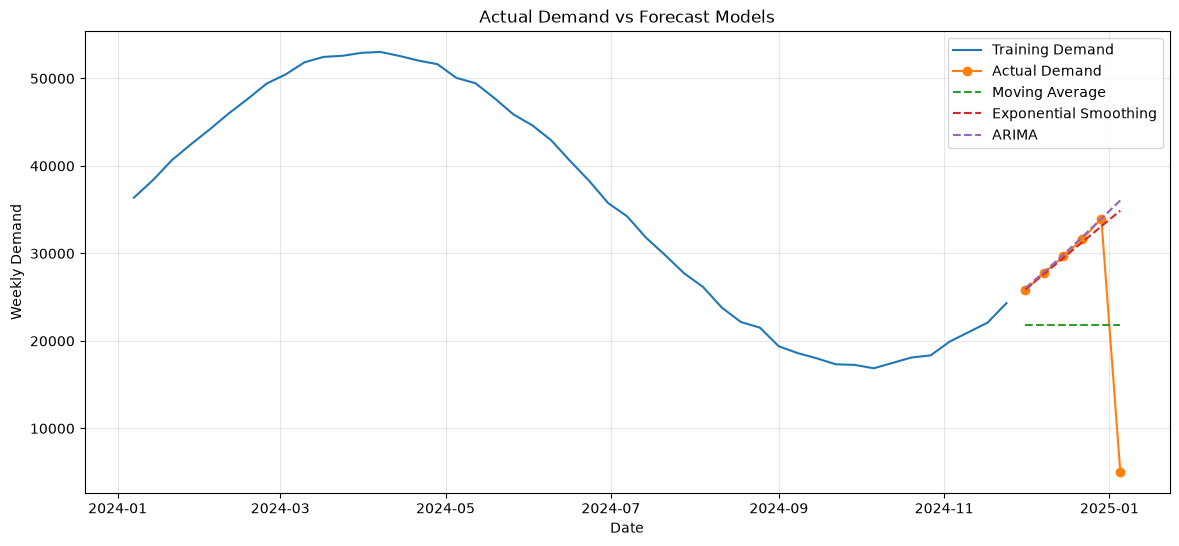

In [25]:
plt.figure(figsize=(14, 6))

plt.plot(
    train['Date'],
    train['Demand'],
    label='Training Demand'
)

plt.plot(
    test['Date'],
    test['Demand'],
    marker='o',
    label='Actual Demand'
)

plt.plot(
    test['Date'],
    ma_predictions,
    linestyle='--',
    label='Moving Average'
)

plt.plot(
    test['Date'],
    ets_predictions,
    linestyle='--',
    label='Exponential Smoothing'
)

plt.plot(
    test['Date'],
    arima_predictions,
    linestyle='--',
    label='ARIMA'
)

plt.title('Actual Demand vs Forecast Models')
plt.xlabel('Date')
plt.ylabel('Weekly Demand')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(IMAGE_DIR / "03_actual_vs_forecast_models.png", dpi=300, bbox_inches="tight")

plt.show()

### Interpretation — Actual vs Forecast Models
This chart compares observed test-period demand with Moving Average, Exponential Smoothing and ARIMA forecasts. The MAE, RMSE and MAPE results should be used with this visual to select the model that tracks actual demand most accurately.

### 11. Forecast the Next 1, 3 and 6 Periods

In [26]:
# 11. FUTURE DEMAND FORECAST

forecast_horizon = 6

if best_model == 'Moving Average':

    forecast_value = (
        weekly_demand['Demand']
        .tail(4)
        .mean()
    )

    future_forecast = np.repeat(
        forecast_value,
        forecast_horizon
    )


elif best_model == 'Exponential Smoothing':

    final_model = ExponentialSmoothing(
        weekly_demand['Demand'],
        trend='add',
        seasonal=None,
        initialization_method='estimated'
    ).fit()

    future_forecast = final_model.forecast(
        forecast_horizon
    )


else:

    final_model = ARIMA(
        weekly_demand['Demand'],
        order=(2, 1, 2)
    ).fit()

    future_forecast = final_model.forecast(
        forecast_horizon
    )

In [27]:
future_dates = pd.date_range(
    start=weekly_demand['Date'].max() + pd.Timedelta(weeks=1),
    periods=6,
    freq='W'
)

forecast_table = pd.DataFrame({
    'Period': range(1, 7),
    'Date': future_dates,
    'Forecast_Demand': np.asarray(future_forecast).flatten()
})

# Prevent negative forecasts
forecast_table['Forecast_Demand'] = (
    forecast_table['Forecast_Demand']
    .clip(lower=0)
    .round(0)
)

display(forecast_table)

,Period,Date,Forecast_Demand
0,1,2025-01-12,25080.0
1,2,2025-01-19,25080.0
2,3,2025-01-26,25080.0
3,4,2025-02-02,25080.0
4,5,2025-02-09,25080.0
5,6,2025-02-16,25080.0


In [28]:
forecast_1_period = forecast_table.iloc[:1]['Forecast_Demand'].sum()
forecast_3_periods = forecast_table.iloc[:3]['Forecast_Demand'].sum()
forecast_6_periods = forecast_table.iloc[:6]['Forecast_Demand'].sum()

print(f"Expected demand next 1 period: {forecast_1_period:,.0f} units")
print(f"Expected demand next 3 periods: {forecast_3_periods:,.0f} units")
print(f"Expected demand next 6 periods: {forecast_6_periods:,.0f} units")

Expected demand next 1 period: 25,080 units
Expected demand next 3 periods: 75,240 units
Expected demand next 6 periods: 150,480 units


### 12. SKU-Warehouse Demand Forecast

SKU × Warehouse demand


In [29]:
# Use recent 28 days to estimate current demand behaviour

recent_start = df['Date'].max() - pd.Timedelta(days=27)

recent_df = df[
    df['Date'] >= recent_start
].copy()

sku_wh_demand = (
    recent_df
    .groupby(['SKU_ID', 'Warehouse_ID'])
    .agg(
        Avg_Daily_Demand=('Units_Sold', 'mean'),
        Demand_Std=('Units_Sold', 'std'),
        Recent_28D_Demand=('Units_Sold', 'sum')
    )
    .reset_index()
)

sku_wh_demand['Forecast_7D'] = (
    sku_wh_demand['Avg_Daily_Demand'] * 7
)

sku_wh_demand['Forecast_21D'] = (
    sku_wh_demand['Avg_Daily_Demand'] * 21
)

sku_wh_demand['Forecast_42D'] = (
    sku_wh_demand['Avg_Daily_Demand'] * 42
)

display(sku_wh_demand.head(10))

,SKU_ID,Warehouse_ID,Avg_Daily_Demand,Demand_Std,Recent_28D_Demand,Forecast_7D,Forecast_21D,Forecast_42D
0,SKU_1,WH_1,16.785714,5.065184,470,117.50,352.50,705.0
1,SKU_1,WH_2,17.500000,5.594309,490,122.50,367.50,735.0
2,SKU_1,WH_3,18.142857,4.632528,508,127.00,381.00,762.0
3,SKU_1,WH_4,18.642857,6.007491,522,130.50,391.50,783.0
4,SKU_1,WH_5,18.321429,6.134623,513,128.25,384.75,769.5
5,SKU_10,WH_1,16.571429,4.442460,464,116.00,348.00,696.0
6,SKU_10,WH_2,17.535714,4.104940,491,122.75,368.25,736.5
7,SKU_10,WH_3,20.107143,6.100026,563,140.75,422.25,844.5
8,SKU_10,WH_4,17.928571,6.468892,502,125.50,376.50,753.0
9,SKU_10,WH_5,19.178571,5.284874,537,134.25,402.75,805.5


### 13. Get Current Inventory Position

In [30]:
latest_inventory = (
    df.sort_values('Date')
      .groupby(['SKU_ID', 'Warehouse_ID'])
      .tail(1)
      [[
          'SKU_ID',
          'Warehouse_ID',
          'Supplier_ID',
          'Region',
          'Inventory_Level',
          'Supplier_Lead_Time_Days',
          'Unit_Cost',
          'Unit_Price'
      ]]
)

inventory_model = latest_inventory.merge(
    sku_wh_demand,
    on=['SKU_ID', 'Warehouse_ID'],
    how='left'
)

display(inventory_model.head())

,SKU_ID,Warehouse_ID,Supplier_ID,Region,Inventory_Level,Supplier_Lead_Time_Days,Unit_Cost,Unit_Price,Avg_Daily_Demand,Demand_Std,Recent_28D_Demand,Forecast_7D,Forecast_21D,Forecast_42D
0,SKU_31,WH_5,SUP_5,East,415,4,8.04,13.58,17.964286,4.910172,503,125.75,377.25,754.5
1,SKU_9,WH_3,SUP_10,East,533,14,10.01,15.85,18.357143,4.347961,514,128.50,385.50,771.0
2,SKU_25,WH_5,SUP_8,East,373,7,8.45,14.29,16.428571,4.764285,460,115.00,345.00,690.0
3,SKU_25,WH_4,SUP_6,East,375,9,12.02,19.24,18.500000,7.125853,518,129.50,388.50,777.0
4,SKU_25,WH_3,SUP_1,North,252,7,6.51,8.04,16.678571,5.894464,467,116.75,350.25,700.5


### 14. Safety Stock

We'll use a 95% service-level assumption.

In [31]:
SERVICE_LEVEL_Z = 1.645

inventory_model['Safety_Stock'] = (
    SERVICE_LEVEL_Z
    * inventory_model['Demand_Std']
    * np.sqrt(
        inventory_model['Supplier_Lead_Time_Days']
    )
)

inventory_model['Safety_Stock'] = (
    inventory_model['Safety_Stock']
    .fillna(0)
    .round()
)

The logic is:
Safety stock = Z × demand variability × √lead time
This protects inventory against demand uncertainty while waiting for the supplier.

In [32]:

inventory_model['Lead_Time_Demand'] = (
    inventory_model['Avg_Daily_Demand']
    * inventory_model['Supplier_Lead_Time_Days']
)

inventory_model['Calculated_ROP'] = (
    inventory_model['Lead_Time_Demand']
    + inventory_model['Safety_Stock']
)

inventory_model['Calculated_ROP'] = (
    np.ceil(inventory_model['Calculated_ROP'])
)

In [33]:
inventory_model['Reorder_Now'] = np.where(
    inventory_model['Inventory_Level']
    <= inventory_model['Calculated_ROP'],
    'YES',
    'NO'
)

### 15.1 Visualising the Reorder Point Decision

The illustration below uses an **actual SKU–warehouse combination from the dataset** rather than hard-coded inventory assumptions. It automatically selects a suitable active item and visualises its current inventory, average daily demand, supplier lead time, safety stock, calculated reorder point, order trigger and expected delivery point.


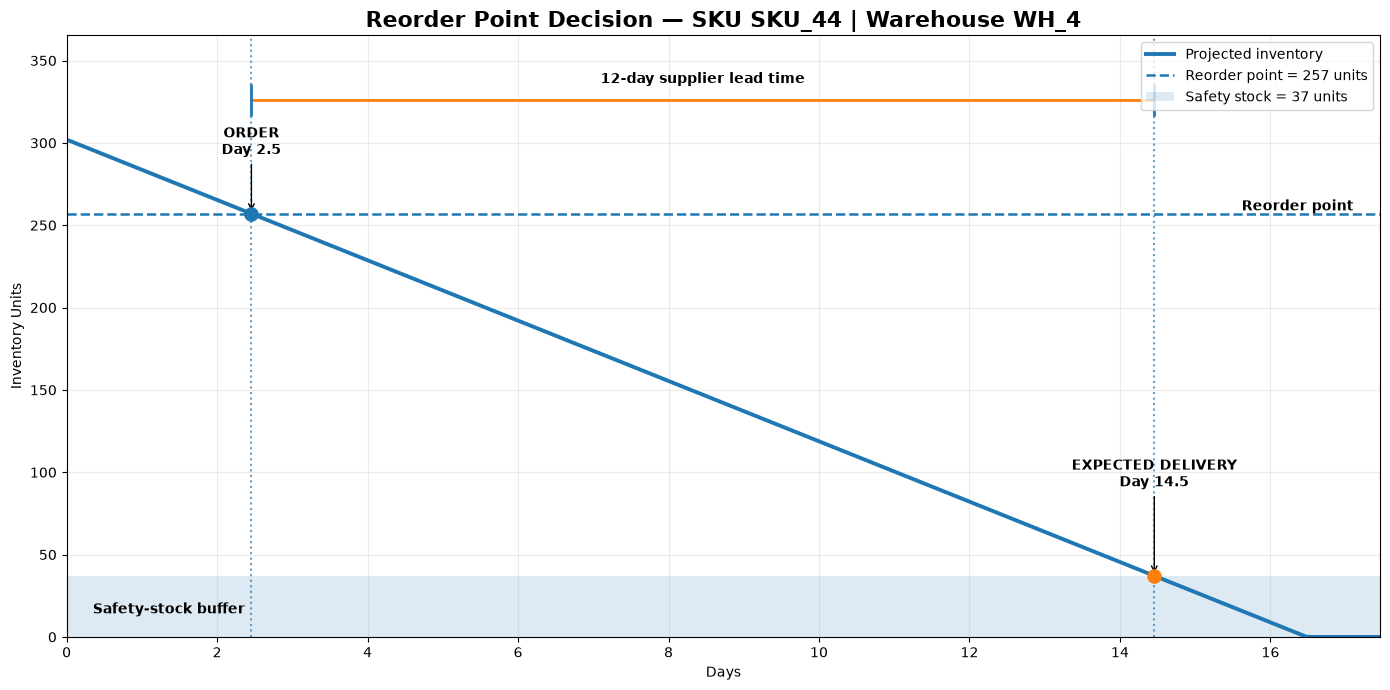

SKU: SKU_44
Warehouse: WH_4
Current inventory: 302 units
Average daily demand: 18.32 units/day
Supplier lead time: 12 days
Safety stock: 37 units
Calculated reorder point: 257 units
Estimated order trigger: day 2.5
Expected replenishment arrival: day 14.5


In [34]:
# ============================================================
# 15.1 DATA-DRIVEN REORDER POINT ILLUSTRATION
# ============================================================

# Select a real SKU–warehouse combination that:
# 1) has positive demand,
# 2) currently sits above its reorder point, and
# 3) is expected to reach the reorder point within a useful planning horizon.

rop_candidates = inventory_model[
    (inventory_model['Avg_Daily_Demand'] > 0) &
    (inventory_model['Supplier_Lead_Time_Days'] > 0) &
    (inventory_model['Inventory_Level'] > inventory_model['Calculated_ROP'])
].copy()

rop_candidates['Days_to_ROP'] = (
    (rop_candidates['Inventory_Level'] - rop_candidates['Calculated_ROP'])
    / rop_candidates['Avg_Daily_Demand']
)

# Prefer an example approaching its reorder point within the next 14 days.
near_term = rop_candidates[
    rop_candidates['Days_to_ROP'].between(1, 14)
].copy()

if not near_term.empty:
    example = near_term.sort_values('Days_to_ROP').iloc[0]
elif not rop_candidates.empty:
    example = rop_candidates.sort_values('Days_to_ROP').iloc[0]
else:
    # Fallback: use the first valid positive-demand item.
    example = (
        inventory_model[inventory_model['Avg_Daily_Demand'] > 0]
        .sort_values('Inventory_Level', ascending=False)
        .iloc[0]
    )

sku = example['SKU_ID']
warehouse = example['Warehouse_ID']
initial_inventory = float(example['Inventory_Level'])
daily_demand = float(example['Avg_Daily_Demand'])
lead_time = float(example['Supplier_Lead_Time_Days'])
safety_stock = float(example['Safety_Stock'])
reorder_point = float(example['Calculated_ROP'])

# When inventory is already below ROP, the order trigger is today.
order_day = max((initial_inventory - reorder_point) / daily_demand, 0)
delivery_day = order_day + lead_time

# Expected inventory immediately before replenishment arrives.
delivery_inventory = max(
    initial_inventory - daily_demand * delivery_day,
    0
)

# Extend the chart slightly beyond expected delivery.
chart_end = max(delivery_day + 3, 10)
days = np.linspace(0, chart_end, 250)
inventory_path = np.maximum(initial_inventory - daily_demand * days, 0)

fig, ax = plt.subplots(figsize=(14, 7))

# Inventory depletion path
ax.plot(
    days,
    inventory_path,
    linewidth=2.8,
    label='Projected inventory'
)

# Reorder point
ax.axhline(
    reorder_point,
    linestyle='--',
    linewidth=1.8,
    label=f'Reorder point = {reorder_point:,.0f} units'
)

# Safety-stock zone
ax.axhspan(
    0,
    safety_stock,
    alpha=0.15,
    label=f'Safety stock = {safety_stock:,.0f} units'
)

# Order and delivery markers
ax.scatter(order_day, reorder_point, s=90, zorder=5)
ax.scatter(delivery_day, delivery_inventory, s=90, zorder=5)

ax.axvline(order_day, linestyle=':', alpha=0.7)
ax.axvline(delivery_day, linestyle=':', alpha=0.7)

# Lead-time bracket
bracket_y = initial_inventory * 1.08
ax.plot(
    [order_day, delivery_day],
    [bracket_y, bracket_y],
    linewidth=2
)
ax.vlines(
    [order_day, delivery_day],
    bracket_y * 0.97,
    bracket_y * 1.03,
    linewidth=2
)

ax.text(
    (order_day + delivery_day) / 2,
    bracket_y * 1.025,
    f'{lead_time:.0f}-day supplier lead time',
    ha='center',
    va='bottom',
    fontweight='bold'
)

# Point annotations
ax.annotate(
    f'ORDER\nDay {order_day:.1f}',
    xy=(order_day, reorder_point),
    xytext=(order_day, reorder_point + initial_inventory * 0.12),
    ha='center',
    fontweight='bold',
    arrowprops=dict(arrowstyle='->')
)

ax.annotate(
    f'EXPECTED DELIVERY\nDay {delivery_day:.1f}',
    xy=(delivery_day, delivery_inventory),
    xytext=(delivery_day, delivery_inventory + initial_inventory * 0.18),
    ha='center',
    fontweight='bold',
    arrowprops=dict(arrowstyle='->')
)

ax.text(
    chart_end * 0.98,
    reorder_point,
    '  Reorder point',
    va='bottom',
    ha='right',
    fontweight='bold'
)

ax.text(
    chart_end * 0.02,
    safety_stock * 0.45,
    'Safety-stock buffer',
    va='center',
    fontweight='bold'
)

ax.set_title(
    f'Reorder Point Decision — SKU {sku} | Warehouse {warehouse}',
    fontsize=16,
    fontweight='bold'
)
ax.set_xlabel('Days')
ax.set_ylabel('Inventory Units')
ax.set_xlim(0, chart_end)
ax.set_ylim(0, bracket_y * 1.12)
ax.grid(alpha=0.25)
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig(IMAGE_DIR / "04_reorder_point_decision.png", dpi=300, bbox_inches="tight")

plt.show()

print(f"SKU: {sku}")
print(f"Warehouse: {warehouse}")
print(f"Current inventory: {initial_inventory:,.0f} units")
print(f"Average daily demand: {daily_demand:,.2f} units/day")
print(f"Supplier lead time: {lead_time:.0f} days")
print(f"Safety stock: {safety_stock:,.0f} units")
print(f"Calculated reorder point: {reorder_point:,.0f} units")
print(f"Estimated order trigger: day {order_day:.1f}")
print(f"Expected replenishment arrival: day {delivery_day:.1f}")


### Interpretation — When should we reorder?

The reorder point represents the inventory level at which a replenishment order should be placed. It combines **expected demand during supplier lead time + safety stock**. The declining line represents projected inventory consumption over time. When inventory reaches the reorder point, the purchase order is triggered. Inventory then continues to decline during the supplier lead time, while the safety-stock buffer protects the operation against demand variability until replenishment arrives.

Because this illustration is generated from an actual SKU–warehouse record, the order trigger and delivery timing change automatically when the underlying demand, inventory, lead-time or safety-stock calculations change. This directly answers the inventory decision question: **reorder when projected available inventory reaches the calculated reorder point—not when stock reaches zero.**


### 16. How Much Should We Order?

order-up-to policy.
Let's replenish enough stock to cover:
Lead time + 28 days of demand + safety stock.

In [35]:
REVIEW_PERIOD_DAYS = 28

inventory_model['Target_Inventory'] = (
    inventory_model['Avg_Daily_Demand']
    * (
        inventory_model['Supplier_Lead_Time_Days']
        + REVIEW_PERIOD_DAYS
    )
    + inventory_model['Safety_Stock']
)

inventory_model['Recommended_Order_Qty'] = np.where(
    inventory_model['Reorder_Now'] == 'YES',
    
    np.maximum(
        inventory_model['Target_Inventory']
        - inventory_model['Inventory_Level'],
        0
    ),
    
    0
)

inventory_model['Recommended_Order_Qty'] = (
    np.ceil(
        inventory_model['Recommended_Order_Qty']
    )
)

### 17. Days of Inventory Cover

In [36]:
inventory_model['Days_of_Cover'] = np.where(
    inventory_model['Avg_Daily_Demand'] > 0,

    inventory_model['Inventory_Level']
    / inventory_model['Avg_Daily_Demand'],

    np.inf
)

inventory_model['Days_of_Cover'] = (
    inventory_model['Days_of_Cover'].round(1)
)

### 18. Which Warehouse Needs Replenishment First?

In [37]:
warehouse_priority = (
    inventory_model
    .groupby('Warehouse_ID')
    .agg(
        Total_SKUs=('SKU_ID', 'nunique'),

        SKUs_Requiring_Reorder=(
            'Reorder_Now',
            lambda x: (x == 'YES').sum()
        ),

        Average_Days_Cover=(
            'Days_of_Cover',
            'mean'
        ),

        Recommended_Order_Units=(
            'Recommended_Order_Qty',
            'sum'
        ),

        Current_Inventory=(
            'Inventory_Level',
            'sum'
        )
    )
    .reset_index()
)

In [38]:
# Proportion of SKUs at risk

warehouse_priority['Reorder_Rate_%'] = (
    warehouse_priority['SKUs_Requiring_Reorder']
    / warehouse_priority['Total_SKUs']
    * 100
)

In [39]:
warehouse_priority['Replenishment_Priority'] = (
    warehouse_priority['Average_Days_Cover']
    .rank(method='dense', ascending=True)
    .astype(int)
)

warehouse_priority = warehouse_priority.sort_values('Replenishment_Priority').reset_index(drop=True)

display(warehouse_priority.round({
    'Average_Days_Cover': 1,
    'Recommended_Order_Units': 0,
    'Current_Inventory': 0,
    'Reorder_Rate_%': 1
}))


,Warehouse_ID,Total_SKUs,SKUs_Requiring_Reorder,Average_Days_Cover,Recommended_Order_Units,Current_Inventory,Reorder_Rate_%,Replenishment_Priority
0,WH_1,50,1,24.8,522.0,22110,2.0,1
1,WH_3,50,1,25.0,522.0,22152,2.0,2
2,WH_4,50,1,25.1,552.0,22242,2.0,3
3,WH_5,50,0,26.1,0.0,23011,0.0,4
4,WH_2,50,0,27.8,0.0,24504,0.0,5


### 19. Financial Impact of Potential Stockouts

In [40]:
inventory_model['Projected_Lead_Time_Shortage'] = np.maximum(
    inventory_model['Lead_Time_Demand']
    + inventory_model['Safety_Stock']
    - inventory_model['Inventory_Level'],
    0
)

In [41]:
# Potential lost revenue and gross profit exposure
inventory_model['Potential_Lost_Revenue'] = (
    inventory_model['Projected_Lead_Time_Shortage']
    * inventory_model['Unit_Price']
)

inventory_model['Unit_Margin'] = (
    inventory_model['Unit_Price']
    - inventory_model['Unit_Cost']
)

inventory_model['Potential_Lost_Profit'] = (
    inventory_model['Projected_Lead_Time_Shortage']
    * inventory_model['Unit_Margin']
)


In [42]:
total_shortage_units = (
    inventory_model['Projected_Lead_Time_Shortage'].sum()
)

lost_revenue = (
    inventory_model['Potential_Lost_Revenue'].sum()
)

lost_profit = (
    inventory_model['Potential_Lost_Profit'].sum()
)

print(f"Potential shortage exposure: {total_shortage_units:,.0f} units")
print(f"Potential revenue at risk: {lost_revenue:,.2f}")
print(f"Potential gross profit at risk: {lost_profit:,.2f}")

Potential shortage exposure: 99 units
Potential revenue at risk: 2,024.09
Potential gross profit at risk: 569.12


### 20. Excess Inventory

Excess inventory as inventory exceeding:
Expected 42-day demand + safety stock.

In [43]:
EXCESS_COVER_DAYS = 42

inventory_model['Max_Target_Stock'] = (
    inventory_model['Avg_Daily_Demand']
    * EXCESS_COVER_DAYS
    + inventory_model['Safety_Stock']
)

inventory_model['Excess_Inventory_Units'] = np.maximum(
    inventory_model['Inventory_Level']
    - inventory_model['Max_Target_Stock'],
    0
)

In [44]:
inventory_model['Excess_Inventory_Value'] = (
    inventory_model['Excess_Inventory_Units']
    * inventory_model['Unit_Cost']
)

total_excess_units = (
    inventory_model['Excess_Inventory_Units'].sum()
)

total_excess_value = (
    inventory_model['Excess_Inventory_Value'].sum()
)

print(f"Excess inventory: {total_excess_units:,.0f} units")
print(f"Capital tied up in excess inventory: {total_excess_value:,.2f}")

Excess inventory: 119 units
Capital tied up in excess inventory: 719.92


### 21. Final Inventory Decision Model


In [45]:

decision_model = inventory_model[[
    'SKU_ID',
    'Warehouse_ID',
    'Supplier_ID',
    'Region',

    'Avg_Daily_Demand',
    'Forecast_7D',
    'Forecast_21D',
    'Forecast_42D',

    'Inventory_Level',
    'Days_of_Cover',

    'Supplier_Lead_Time_Days',
    'Lead_Time_Demand',

    'Safety_Stock',
    'Calculated_ROP',

    'Reorder_Now',
    'Recommended_Order_Qty',

    'Projected_Lead_Time_Shortage',
    'Potential_Lost_Revenue',
    'Potential_Lost_Profit',

    'Excess_Inventory_Units',
    'Excess_Inventory_Value'
]].copy()

In [46]:
def inventory_action(row):

    if row['Projected_Lead_Time_Shortage'] > 0:
        return 'URGENT REPLENISHMENT'

    elif row['Reorder_Now'] == 'YES':
        return 'REORDER'

    elif row['Excess_Inventory_Units'] > 0:
        return 'REDUCE / REDISTRIBUTE STOCK'

    else:
        return 'NO ACTION'


decision_model['Recommended_Action'] = (
    decision_model.apply(
        inventory_action,
        axis=1
    )
)

### Priority Score

In [47]:
# 22. REPLENISHMENT PRIORITY SCORE

decision_model['Priority_Score'] = (
    decision_model['Projected_Lead_Time_Shortage']
    * decision_model['Potential_Lost_Profit']
)

decision_model = decision_model.sort_values(
    ['Recommended_Action', 'Priority_Score'],
    ascending=[True, False]
)

display(decision_model.head(20))

,SKU_ID,Warehouse_ID,Supplier_ID,Region,Avg_Daily_Demand,Forecast_7D,Forecast_21D,Forecast_42D,Inventory_Level,Days_of_Cover,Supplier_Lead_Time_Days,Lead_Time_Demand,Safety_Stock,Calculated_ROP,Reorder_Now,Recommended_Order_Qty,Projected_Lead_Time_Shortage,Potential_Lost_Revenue,Potential_Lost_Profit,Excess_Inventory_Units,Excess_Inventory_Value,Recommended_Action,Priority_Score
0,SKU_31,WH_5,SUP_5,East,17.964286,125.75,377.25,754.5,415,23.1,4,71.857143,16.0,88.0,NO,0.0,0.0,0.0,0.0,0.0,0.0,NO ACTION,0.0
1,SKU_9,WH_3,SUP_10,East,18.357143,128.50,385.50,771.0,533,29.0,14,257.000000,27.0,284.0,NO,0.0,0.0,0.0,0.0,0.0,0.0,NO ACTION,0.0
2,SKU_25,WH_5,SUP_8,East,16.428571,115.00,345.00,690.0,373,22.7,7,115.000000,21.0,136.0,NO,0.0,0.0,0.0,0.0,0.0,0.0,NO ACTION,0.0
3,SKU_25,WH_4,SUP_6,East,18.500000,129.50,388.50,777.0,375,20.3,9,166.500000,35.0,202.0,NO,0.0,0.0,0.0,0.0,0.0,0.0,NO ACTION,0.0
4,SKU_25,WH_3,SUP_1,North,16.678571,116.75,350.25,700.5,252,15.1,7,116.750000,26.0,143.0,NO,0.0,0.0,0.0,0.0,0.0,0.0,NO ACTION,0.0
6,SKU_25,WH_1,SUP_10,South,17.178571,120.25,360.75,721.5,595,34.6,5,85.892857,27.0,113.0,NO,0.0,0.0,0.0,0.0,0.0,0.0,NO ACTION,0.0
7,SKU_24,WH_5,SUP_4,North,18.107143,126.75,380.25,760.5,523,28.9,7,126.750000,33.0,160.0,NO,0.0,0.0,0.0,0.0,0.0,0.0,NO ACTION,0.0
8,SKU_24,WH_4,SUP_3,North,17.357143,121.50,364.50,729.0,321,18.5,13,225.642857,34.0,260.0,NO,0.0,0.0,0.0,0.0,0.0,0.0,NO ACTION,0.0
9,SKU_24,WH_3,SUP_3,South,16.892857,118.25,354.75,709.5,425,25.2,10,168.928571,29.0,198.0,NO,0.0,0.0,0.0,0.0,0.0,0.0,NO ACTION,0.0
10,SKU_24,WH_2,SUP_7,North,17.535714,122.75,368.25,736.5,377,21.5,5,87.678571,23.0,111.0,NO,0.0,0.0,0.0,0.0,0.0,0.0,NO ACTION,0.0


In [48]:
decision_model['Priority_Score'] = (
    decision_model['Potential_Lost_Profit']
    / (decision_model['Days_of_Cover'] + 1)
)

decision_model = decision_model.sort_values(
    'Priority_Score',
    ascending=False
)

### 23. Management Summary

In [49]:
summary = pd.DataFrame({

    'KPI': [
        'SKU-Warehouse Combinations',
        'Combinations Requiring Reorder',
        'Recommended Purchase Quantity',
        'Potential Shortage Units',
        'Potential Revenue at Risk',
        'Potential Gross Profit at Risk',
        'Excess Inventory Units',
        'Capital Tied Up in Excess Inventory'
    ],

    'Value': [

        len(decision_model),

        (decision_model['Reorder_Now'] == 'YES').sum(),

        decision_model[
            'Recommended_Order_Qty'
        ].sum(),

        decision_model[
            'Projected_Lead_Time_Shortage'
        ].sum(),

        decision_model[
            'Potential_Lost_Revenue'
        ].sum(),

        decision_model[
            'Potential_Lost_Profit'
        ].sum(),

        decision_model[
            'Excess_Inventory_Units'
        ].sum(),

        decision_model[
            'Excess_Inventory_Value'
        ].sum()
    ]
})

display(summary)

,KPI,Value
0,SKU-Warehouse Combinations,250.000000
1,Combinations Requiring Reorder,3.000000
2,Recommended Purchase Quantity,1596.000000
3,Potential Shortage Units,99.214286
4,Potential Revenue at Risk,2024.086429
5,Potential Gross Profit at Risk,569.125000
6,Excess Inventory Units,119.500000
7,Capital Tied Up in Excess Inventory,719.925000


### 24. Visualize Replenishment Priority

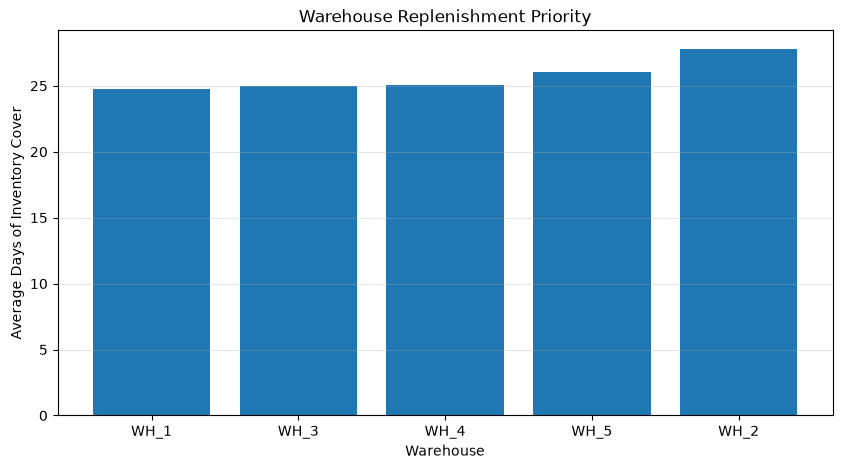

In [50]:
plt.figure(figsize=(10, 5))

priority_plot = warehouse_priority.sort_values(
    'Average_Days_Cover'
)

plt.bar(
    priority_plot['Warehouse_ID'],
    priority_plot['Average_Days_Cover']
)

plt.title('Warehouse Replenishment Priority')
plt.xlabel('Warehouse')
plt.ylabel('Average Days of Inventory Cover')

plt.grid(axis='y', alpha=0.3)
plt.savefig(IMAGE_DIR / "05_warehouse_replenishment_priority.png", dpi=300, bbox_inches="tight")

plt.show()

### Interpretation — Warehouse Replenishment Priority
Average days of inventory cover estimates how long current stock can support expected demand. Warehouses with fewer days of cover require earlier replenishment attention, subject to SKU-level lead time and safety-stock requirements.

### 25. Visualize Inventory Actions

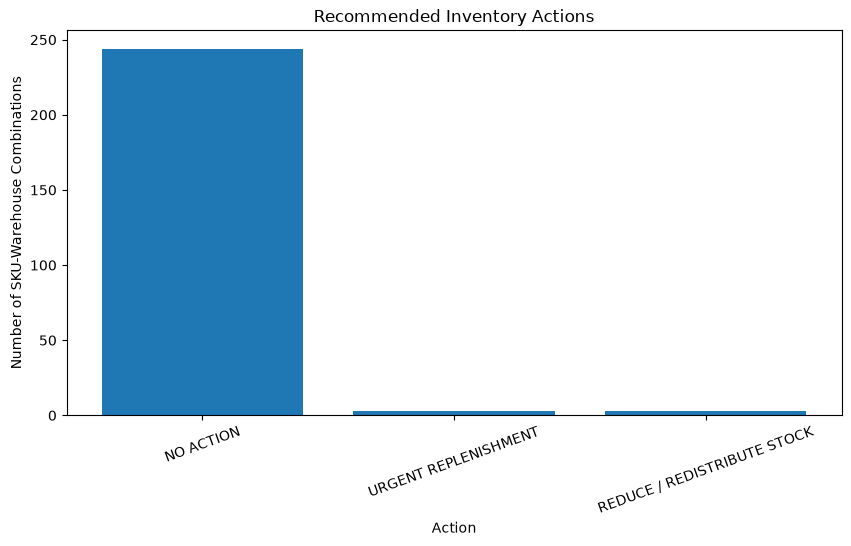

In [51]:
action_counts = (
    decision_model['Recommended_Action']
    .value_counts()
)

plt.figure(figsize=(10, 5))

plt.bar(
    action_counts.index,
    action_counts.values
)

plt.title('Recommended Inventory Actions')
plt.xlabel('Action')
plt.ylabel('Number of SKU-Warehouse Combinations')

plt.xticks(rotation=20)
plt.savefig(IMAGE_DIR / "06_recommended_inventory_actions.png", dpi=300, bbox_inches="tight")

plt.show()

### Interpretation — Recommended Inventory Actions
This chart summarizes the number of SKU–warehouse combinations requiring each action. Urgent replenishment signals projected lead-time shortage exposure; Reorder indicates the reorder trigger has been reached; Reduce / Redistribute identifies excess stock; and No Action indicates an acceptable current position.

### 26. Top 15 Replenishment Risks

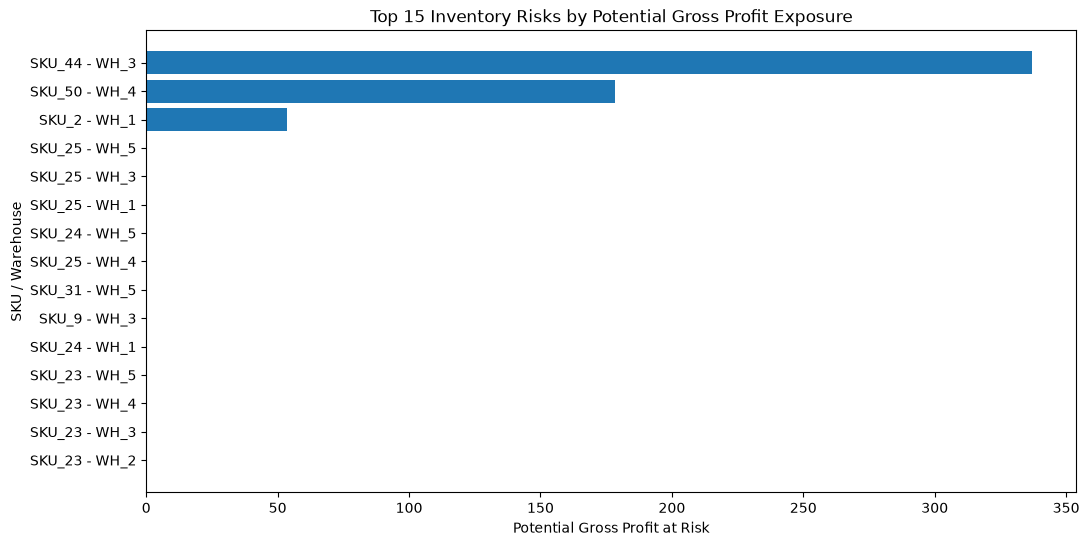

In [52]:
top_risks = (
    decision_model
    .sort_values(
        'Priority_Score',
        ascending=False
    )
    .head(15)
)

plt.figure(figsize=(12, 6))

labels = (
    top_risks['SKU_ID'].astype(str)
    + ' - '
    + top_risks['Warehouse_ID'].astype(str)
)

plt.barh(
    labels,
    top_risks['Potential_Lost_Profit']
)

plt.title('Top 15 Inventory Risks by Potential Gross Profit Exposure')
plt.xlabel('Potential Gross Profit at Risk')
plt.ylabel('SKU / Warehouse')

plt.gca().invert_yaxis()
plt.savefig(IMAGE_DIR / "07_top_15_inventory_risks.png", dpi=300, bbox_inches="tight")

plt.show()

### Interpretation — Top Inventory Risks
This chart ranks SKU–warehouse combinations by potential gross-profit exposure. Larger values indicate greater commercial risk if forecast demand cannot be served, helping procurement focus on financially important shortages first.

# Additional Decision Visualisations
These charts translate the inventory calculations into management-friendly decisions. Each chart is immediately followed by a concise interpretation.

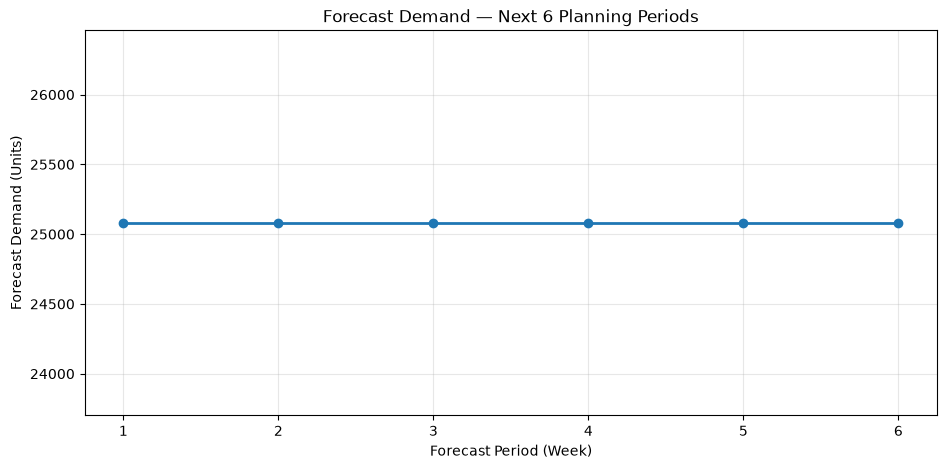

In [53]:
# Forecast for the next six planning periods
plt.figure(figsize=(11,5))
plt.plot(forecast_table['Period'], forecast_table['Forecast_Demand'], marker='o', linewidth=2)
plt.title('Forecast Demand — Next 6 Planning Periods')
plt.xlabel('Forecast Period (Week)'); plt.ylabel('Forecast Demand (Units)')
plt.xticks(forecast_table['Period']); plt.grid(alpha=0.3); plt.savefig(IMAGE_DIR / "08_six_period_demand_forecast.png", dpi=300, bbox_inches="tight")

plt.show()

### Interpretation — Six-Period Demand Forecast
This chart shows expected demand for the next six weekly planning periods. It provides a forward view for purchasing, replenishment scheduling and capacity planning rather than relying only on historical demand.

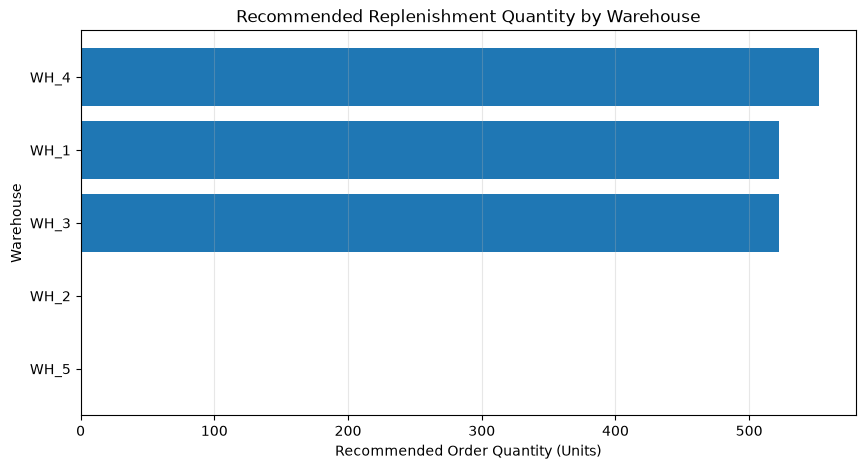

In [54]:
# Recommended replenishment quantity by warehouse
p=warehouse_priority.sort_values('Recommended_Order_Units')
plt.figure(figsize=(10,5)); plt.barh(p['Warehouse_ID'],p['Recommended_Order_Units'])
plt.title('Recommended Replenishment Quantity by Warehouse')
plt.xlabel('Recommended Order Quantity (Units)'); plt.ylabel('Warehouse')
plt.grid(axis='x',alpha=0.3); plt.savefig(IMAGE_DIR / "09_replenishment_quantity_by_warehouse.png", dpi=300, bbox_inches="tight")

plt.show()

### Interpretation — Recommended Replenishment by Warehouse
This chart shows how many units the model recommends ordering for each warehouse after considering current inventory, demand, lead time, reorder point and target stock. A larger requirement reflects the current stock-and-demand position, not necessarily poor warehouse performance.

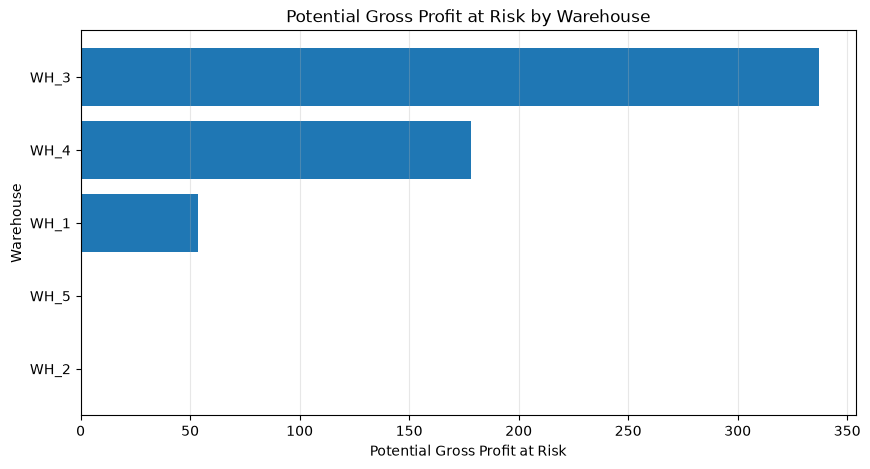

In [55]:
# Potential gross-profit exposure by warehouse
w=(inventory_model.groupby('Warehouse_ID',as_index=False)
   .agg(Potential_Lost_Profit=('Potential_Lost_Profit','sum'))
   .sort_values('Potential_Lost_Profit'))
plt.figure(figsize=(10,5)); plt.barh(w['Warehouse_ID'],w['Potential_Lost_Profit'])
plt.title('Potential Gross Profit at Risk by Warehouse')
plt.xlabel('Potential Gross Profit at Risk'); plt.ylabel('Warehouse')
plt.grid(axis='x',alpha=0.3); plt.savefig(IMAGE_DIR / "10_gross_profit_at_risk_by_warehouse.png", dpi=300, bbox_inches="tight")

plt.show()

### Interpretation — Potential Stockout Financial Exposure
This is a **risk estimate, not a record of historical losses**. Because the dataset records no observed stockouts, the model estimates gross profit exposed where projected lead-time requirements exceed available inventory. Higher exposure indicates a stronger financial reason to address the potential shortage.

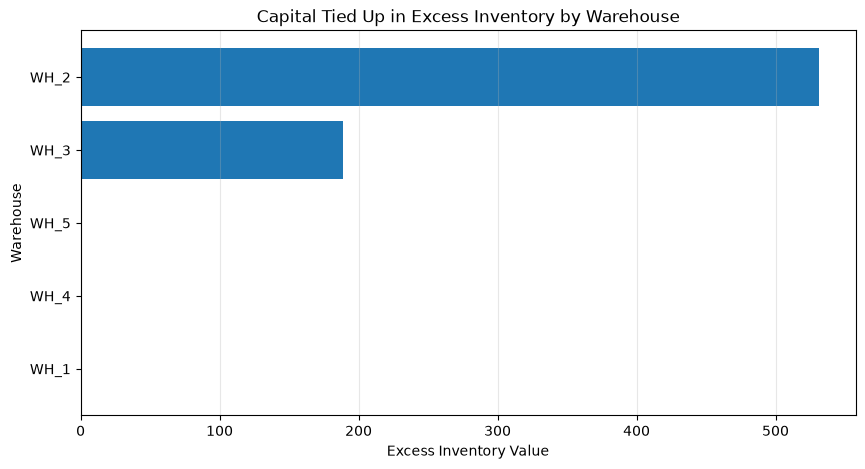

In [56]:
# Excess inventory value by warehouse
w=(inventory_model.groupby('Warehouse_ID',as_index=False)
   .agg(Excess_Inventory_Value=('Excess_Inventory_Value','sum'))
   .sort_values('Excess_Inventory_Value'))
plt.figure(figsize=(10,5)); plt.barh(w['Warehouse_ID'],w['Excess_Inventory_Value'])
plt.title('Capital Tied Up in Excess Inventory by Warehouse')
plt.xlabel('Excess Inventory Value'); plt.ylabel('Warehouse')
plt.grid(axis='x',alpha=0.3); plt.savefig(IMAGE_DIR / "11_excess_inventory_value_by_warehouse.png", dpi=300, bbox_inches="tight")

plt.show()

### Interpretation — Excess Inventory
This chart identifies where inventory exceeds the defined target coverage. Higher values represent more working capital tied up above the desired stock position and may indicate opportunities to reduce future purchasing or redistribute stock.

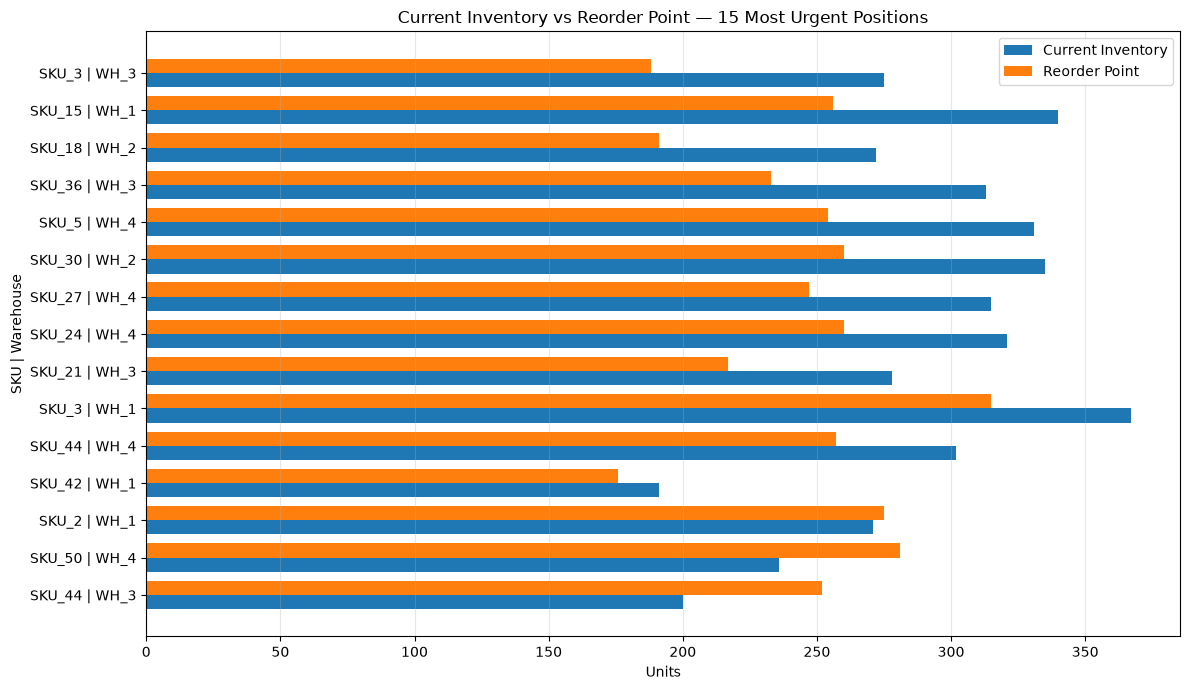

In [57]:
# ============================================================
# CURRENT INVENTORY VS REORDER POINT
# 15 MOST URGENT SKU-WAREHOUSE POSITIONS
# ============================================================

# Calculate the gap between current inventory and reorder point
r = (
    inventory_model
    .assign(
        ROP_Gap=lambda x: (
            x['Inventory_Level'] - x['Calculated_ROP']
        ),
        SKU_Warehouse=lambda x: (
            x['SKU_ID'].astype(str)
            + ' | '
            + x['Warehouse_ID'].astype(str)
        )
    )
    .sort_values('ROP_Gap')
    .head(15)
)

# Chart positions
y = np.arange(len(r))
h = 0.38

# Create chart
plt.figure(figsize=(12, 7))

plt.barh(
    y - h/2,
    r['Inventory_Level'],
    height=h,
    label='Current Inventory'
)

plt.barh(
    y + h/2,
    r['Calculated_ROP'],
    height=h,
    label='Reorder Point'
)

# Labels and formatting
plt.yticks(
    y,
    r['SKU_Warehouse']
)

plt.title(
    'Current Inventory vs Reorder Point — 15 Most Urgent Positions'
)

plt.xlabel('Units')
plt.ylabel('SKU | Warehouse')

plt.legend()

plt.grid(
    axis='x',
    alpha=0.3
)

# Improve spacing
plt.tight_layout()

# Save chart to Images folder
# Display chart
plt.savefig(IMAGE_DIR / "12_inventory_vs_reorder_point.png", dpi=300, bbox_inches="tight")

plt.show()

### Interpretation — Current Inventory vs Reorder Point
The reorder point represents expected demand during supplier lead time plus safety stock. When current inventory is at or below the reorder point, the SKU–warehouse combination has reached its replenishment trigger. This directly visualizes the **“when should we reorder?”** decision.

### 27. Export Final Results




In [58]:
# Export final analytical outputs
decision_model.to_csv("inventory_optimization_recommendations.csv", index=False)
warehouse_priority.to_csv("warehouse_replenishment_priority.csv", index=False)
forecast_table.to_csv("future_demand_forecast.csv", index=False)

print("Export complete:")
print("- inventory_optimization_recommendations.csv")
print("- warehouse_replenishment_priority.csv")
print("- future_demand_forecast.csv")
print(f"- 12 chart images saved in: {IMAGE_DIR.resolve()}")


Export complete:
- inventory_optimization_recommendations.csv
- warehouse_replenishment_priority.csv
- future_demand_forecast.csv
- 12 chart images saved in: C:\Users\pc\Documents\PC 1\Documents\JW work\python\python for data analytics and data app\MSCP\Project 1Inventory analysis\Images
